# Experiment 009: 1.5B SFT-to-GRPO analysis plots

Checking all three 1.5B seeds, plots the training and evaluation results,
and compares the middle scale with the matched 0.5B and 3B experiments.
Generative exact match is the main outcome and the letter probe stays diagnostic.

In [1]:
# load all three 009 seeds and the matched scale results
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "config.py").exists():
    raise FileNotFoundError("repository root containing config.py was not found")
sys.path.insert(0, str(ROOT))

from analysis.stats import align_pred_rows, holm, mcnemar_exact, paired_delta_ci
from data.subjects import TIERS as VALIDATED_TIERS
from eval.metrics import bootstrap_ci

RES = ROOT / "results"
SEEDS = (0, 1, 2)
R9 = {seed: RES / f"009_COLAB_FULL_B15_sft_grpo_seed{seed}" for seed in SEEDS}
B9 = RES / "base_evals" / "009_COLAB_FULL_B15"
FIG = ROOT / "analysis" / "figures" / "009_1"
FIG.mkdir(parents=True, exist_ok=True)

SCALE_RUNS = {
    "0.5B": {
        "params": 0.5,
        "seeds": (0, 1, 2),
        "runs": {seed: RES / f"006_COLAB_FULL_B05_sft_grpo_seed{seed}" for seed in (0, 1, 2)},
        "base": RES / "base_evals" / "006_COLAB_FULL_B05",
    },
    "1.5B": {
        "params": 1.5,
        "seeds": SEEDS,
        "runs": R9,
        "base": B9,
    },
    "3B": {
        "params": 3.0,
        "seeds": (0, 1, 2),
        "runs": {seed: RES / f"003_COLAB_FULL_B3_sft_grpo_seed{seed}" for seed in (0, 1, 2)},
        "base": RES / "base_evals" / "003_COLAB_FULL_B3",
    },
}

plt.style.use("seaborn-v0_8-whitegrid")
COLORS = {"base": "#4C78A8", "sft": "#54A24B", "grpo": "#F58518"}
SEED_COLORS = {0: "#4C78A8", 1: "#F58518", 2: "#54A24B"}
SEED_STYLES = {0: "-", 1: "--", 2: "-."}
TIER_COLORS = {"easy": "#59A14F", "medium": "#F28E2B", "hard": "#E15759"}
TIERS = ["easy", "medium", "hard"]
GROUPS = TIERS + ["overall"]
CONDITIONS = ["base", "sft", "grpo"]
CONDITION_LABELS = {"base": "base", "sft": "SFT", "grpo": "SFT + GRPO"}
TIER_LOOKUP = {subject: tier for tier, subjects in VALIDATED_TIERS.items() for subject in subjects}
EXPECTED = {
    "sft_eval.json", "sft_logprob.json", "sft_preds.jsonl", "sft_logprob_preds.jsonl",
    "sft_trainlog.json", "grpo_eval.json", "grpo_logprob.json", "grpo_preds.jsonl",
    "grpo_logprob_preds.jsonl", "grpo_trainlog.json", "summary.json", "manifest.json", "run.log",
}

def jload(path):
    with open(path) as handle:
        return json.load(handle)

def jsonl(path):
    with open(path) as handle:
        rows = [json.loads(line) for line in handle if line.strip()]
    return [{**row, "tier": TIER_LOOKUP[row["subject"]]} for row in rows]

def raw_jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]

def series(trainlog, key):
    rows = [row for row in trainlog if key in row and "step" in row]
    return np.asarray([row["step"] for row in rows]), np.asarray([row[key] for row in rows], dtype=float)

def smooth(values, window=20):
    if len(values) < window:
        return values
    return np.convolve(values, np.ones(window) / window, mode="valid")

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    print("saved", name)

def accuracy(rows):
    return float(np.mean([bool(row["correct"]) for row in rows]))

def group_rows(rows, group):
    return rows if group == "overall" else [row for row in rows if row["tier"] == group]

def group_accuracy(rows, group):
    return accuracy(group_rows(rows, group))

def group_ci(rows, group, seed):
    selected = group_rows(rows, group)
    return bootstrap_ci([row["pred"] for row in selected], [row["gold"] for row in selected], seed=seed)

def paired_correct(rows_a, rows_b, tier=None):
    rows_a, rows_b = align_pred_rows(rows_a, rows_b)
    if tier is not None:
        rows_a = [row for row in rows_a if row["tier"] == tier]
        rows_b = [row for row in rows_b if row["tier"] == tier]
    if len(rows_a) != len(rows_b):
        raise ValueError("paired prediction counts differ")
    for row_a, row_b in zip(rows_a, rows_b):
        if (row_a["subject"], row_a["tier"], row_a["gold"]) != (row_b["subject"], row_b["tier"], row_b["gold"]):
            raise ValueError("paired prediction rows are not aligned")
    return [bool(row["correct"]) for row in rows_a], [bool(row["correct"]) for row in rows_b]

def paired_stats(rows_a, rows_b, seed):
    output = []
    for group in GROUPS:
        tier = None if group == "overall" else group
        correct_a, correct_b = paired_correct(rows_a, rows_b, tier=tier)
        delta, lo, hi = paired_delta_ci(correct_a, correct_b, seed=seed)
        a_only = sum(a and not b for a, b in zip(correct_a, correct_b))
        b_only = sum((not a) and b for a, b in zip(correct_a, correct_b))
        output.append({
            "group": group,
            "delta": delta,
            "ci_lo": lo,
            "ci_hi": hi,
            "sft_only_correct": a_only,
            "grpo_only_correct": b_only,
            "mcnemar_p": mcnemar_exact(a_only, b_only),
        })
    adjusted = holm([row["mcnemar_p"] for row in output[:3]])
    for row, value in zip(output[:3], adjusted):
        row["holm_p_tiers"] = value
    output[-1]["holm_p_tiers"] = np.nan
    return output

def load_run(run_dir, base_dir):
    return {
        "g": jload(run_dir / "grpo_trainlog.json"),
        "s": jload(run_dir / "sft_trainlog.json"),
        "eval": {condition: jload((base_dir if condition == "base" else run_dir) / f"{condition}_eval.json") for condition in CONDITIONS},
        "lp": {condition: jload((base_dir if condition == "base" else run_dir) / f"{condition}_logprob.json") for condition in CONDITIONS},
        "preds": {condition: jsonl((base_dir if condition == "base" else run_dir) / f"{condition}_preds.jsonl") for condition in CONDITIONS},
        "lp_preds": {condition: jsonl((base_dir if condition == "base" else run_dir) / f"{condition}_logprob_preds.jsonl") for condition in CONDITIONS},
        "man": jload(run_dir / "manifest.json"),
        "summary": jload(run_dir / "summary.json"),
        "log": (run_dir / "run.log").read_text(),
    }

D9 = {seed: load_run(R9[seed], B9) for seed in SEEDS}
SCALE_DATA = {
    label: {seed: load_run(info["runs"][seed], info["base"]) for seed in info["seeds"]}
    for label, info in SCALE_RUNS.items()
}
MISSING = {seed: sorted(name for name in EXPECTED if not (R9[seed] / name).exists()) for seed in SEEDS}

for seed in SEEDS:
    data = D9[seed]
    paired_correct(data["preds"]["sft"], data["preds"]["grpo"])
    assert max(row["step"] for row in data["s"] if "step" in row) == 500
    assert len([row for row in data["g"] if "reward" in row]) == 500
    assert all(data["eval"][condition]["n_items"] == 1884 for condition in CONDITIONS)
    assert all(len(data["preds"][condition]) == 1884 for condition in CONDITIONS)
    assert data["man"]["model_id"] == "Qwen/Qwen2.5-1.5B"
    assert data["man"]["resolved_dtype"] == "bfloat16"
    assert "A100" in data["man"]["gpu"]["device"]
    assert data["man"]["git"]["dirty"] is False
    assert data["log"].count("done. total wall time") == 1
    assert not any(term in data["log"].lower() for term in ["traceback", "out of memory", "protocol abort", "keyboardinterrupt"])
    assert not MISSING[seed]

for seed in SEEDS[1:]:
    assert D9[0]["preds"]["base"] == D9[seed]["preds"]["base"]
assert {D9[seed]["man"]["seed"] for seed in SEEDS} == set(SEEDS)
version_keys = ["torch", "trl", "transformers", "peft", "accelerate", "datasets",
                "cais/mmlu@", "openai/gsm8k@"]
reference_versions = {key: D9[0]["man"]["versions"][key] for key in version_keys}
for seed in SEEDS[1:]:
    assert {key: D9[seed]["man"]["versions"][key] for key in version_keys} == reference_versions

print("loaded and checked experiment 009 seeds 0, 1 and 2")
print("figures ->", FIG)


loaded and checked experiment 009 seeds 0, 1 and 2
figures -> /Users/oleggastov/Desktop/University UK/0006_City n St Georges Universities/003_Projects/INM363-IndividualProject-Dissertation/001_Code/analysis/figures/009_1


## 1. Run health and completion


In [2]:
# verify completion, provenance and the final compute records
ledger_path = RES / "compute_ledger.jsonl"
ledger_rows = raw_jsonl(ledger_path) if ledger_path.exists() else []
ledger_tags = {row.get("run_tag") for row in ledger_rows}
unit_path = RES / "colab_units.jsonl"
unit_rows = raw_jsonl(unit_path) if unit_path.exists() else []
unit_notebooks = {"009_colab_1p5b_full", "009_colab_1p5b_seed2"}
unit_records = [row for row in unit_rows if row.get("notebook") in unit_notebooks]
open_unit_records = []
for path in (RES / "open_cu_sessions").glob("*.json"):
    record = jload(path)
    if record.get("notebook") in unit_notebooks:
        open_unit_records.append(record)

health_rows = []
for seed in SEEDS:
    data = D9[seed]
    timings = data["man"]["timings_sec"]
    health_rows.append({
        "seed": seed,
        "SFT last step": max(row["step"] for row in data["s"] if "step" in row),
        "GRPO reward steps": len([row for row in data["g"] if "reward" in row]),
        "items per eval": data["eval"]["grpo"]["n_items"],
        "missing artifacts": len(MISSING[seed]),
        "normal log ending": data["log"].count("done. total wall time") == 1,
        "stage hours": sum(timings.values()) / 3600,
        "GPU": data["man"]["gpu"]["device"],
        "peak VRAM GB": data["man"]["gpu"]["peak_vram_gb"],
        "dtype": data["man"]["resolved_dtype"],
        "git": data["man"]["git"]["commit"][:7],
        "clean": not data["man"]["git"]["dirty"],
        "aggregate ledger row": data["man"]["run_tag"] in ledger_tags,
    })
health_tbl = pd.DataFrame(health_rows).set_index("seed")
display(health_tbl.round(3))
print("009 compute-unit records:", len(unit_records))
display(pd.DataFrame(unit_records))
print("open 009 compute-unit records:", len(open_unit_records))
if open_unit_records:
    display(pd.DataFrame(open_unit_records))


,SFT last step,GRPO reward steps,items per eval,missing artifacts,normal log ending,stage hours,GPU,peak VRAM GB,dtype,git,clean,aggregate ledger row
seed,,,,,,,,,,,,
0,500,500,1884,0,True,5.602,NVIDIA A100-SXM4-80GB,35.134,bfloat16,6d65309,True,True
1,500,500,1884,0,True,5.022,NVIDIA A100-SXM4-80GB,35.134,bfloat16,6d65309,True,True
2,500,500,1884,0,True,4.808,NVIDIA A100-SXM4-80GB,34.830,bfloat16,b46030a,True,True


009 compute-unit records: 3


,session_id,ts_start,notebook,colab_cu_before,ts_end,colab_cu_after,colab_cu_used,closed_on_resume
0,20260720_210944,2026-07-20 21:11,009_colab_1p5b_full,350.18,2026-07-20 21:19,350.18,0.00,True
1,20260720_211926,2026-07-20 21:19,009_colab_1p5b_full,350.18,2026-07-20 21:31,350.18,0.00,True
2,20260720_213054,2026-07-20 21:31,009_colab_1p5b_full,350.18,2026-07-21 10:40,276.19,73.99,True


open 009 compute-unit records: 1


,session_id,ts_start,notebook,colab_cu_before,unit_rate
0,20260802_201926,2026-08-02 20:19,009_colab_1p5b_seed2,494.5,6.77


## 2. Training behaviour


saved fig01_training_rewards


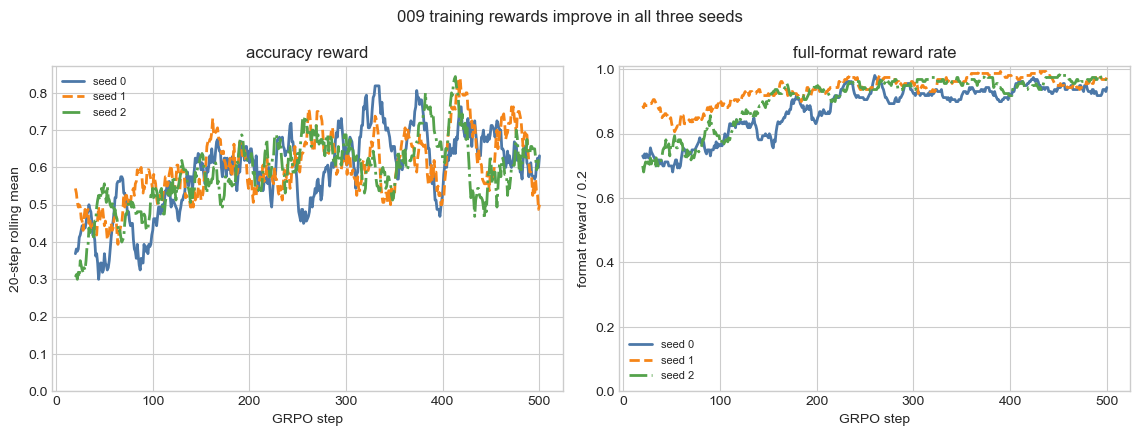

In [3]:
# plot both reward channels across all 500 GRPO steps
window = 20
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
for seed in SEEDS:
    x, values = series(D9[seed]["g"], "rewards/accuracy_reward/mean")
    axes[0].plot(x[window - 1:], smooth(values, window), color=SEED_COLORS[seed],
                 ls=SEED_STYLES[seed], lw=2, label=f"seed {seed}")
    x, values = series(D9[seed]["g"], "rewards/format_reward/mean")
    axes[1].plot(x[window - 1:], smooth(values / 0.2, window), color=SEED_COLORS[seed],
                 ls=SEED_STYLES[seed], lw=2, label=f"seed {seed}")
axes[0].set_title("accuracy reward")
axes[0].set_ylabel("20-step rolling mean")
axes[1].set_title("full-format reward rate")
axes[1].set_ylabel("format reward / 0.2")
for ax in axes:
    ax.set_xlabel("GRPO step")
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=8)
fig.suptitle("009 training rewards improve in all three seeds")
fig.tight_layout()
save(fig, "fig01_training_rewards")
plt.show()


saved fig02_optimisation_health


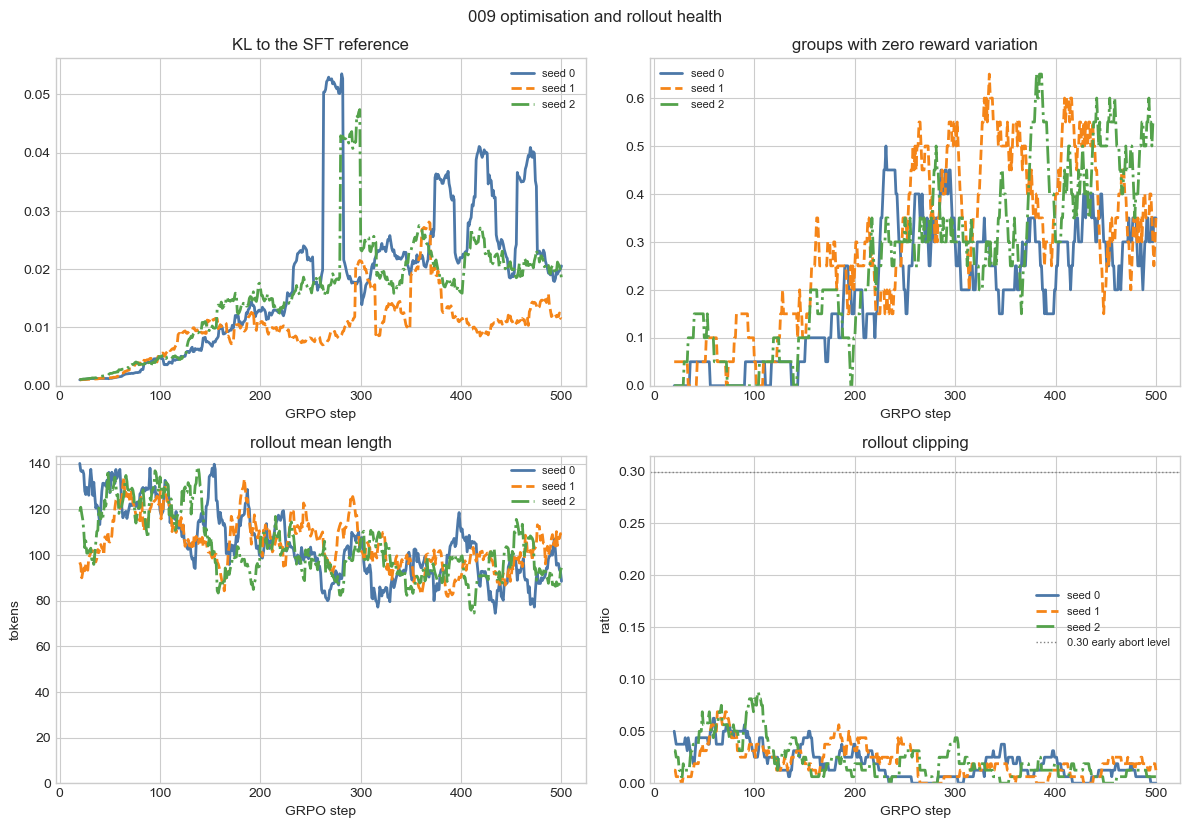

In [4]:
# check policy movement, reward variation, length and clipping
panels = [
    ("kl", "KL to the SFT reference", None),
    ("frac_reward_zero_std", "groups with zero reward variation", None),
    ("completions/mean_length", "rollout mean length", "tokens"),
    ("completions/clipped_ratio", "rollout clipping", "ratio"),
]
fig, axes = plt.subplots(2, 2, figsize=(12, 8.4))
for ax, (key, title, ylabel) in zip(axes.flat, panels):
    for seed in SEEDS:
        x, values = series(D9[seed]["g"], key)
        ax.plot(x[window - 1:], smooth(values, window), color=SEED_COLORS[seed],
                ls=SEED_STYLES[seed], lw=2, label=f"seed {seed}")
    if key == "completions/clipped_ratio":
        ax.axhline(0.3, color="grey", ls=":", lw=1, label="0.30 early abort level")
    ax.set_title(title)
    ax.set_xlabel("GRPO step")
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=8)
fig.suptitle("009 optimisation and rollout health")
fig.tight_layout()
save(fig, "fig02_optimisation_health")
plt.show()


saved fig03_sft_train_val_loss


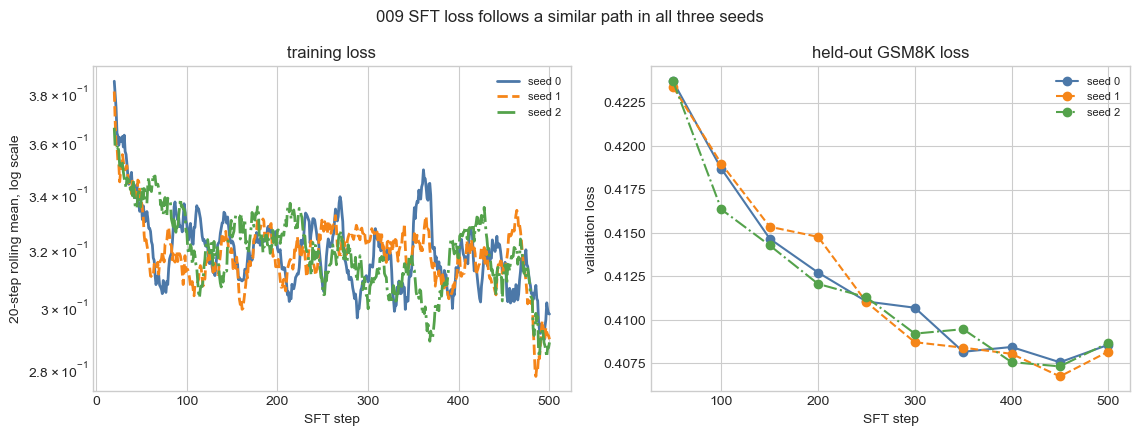

In [5]:
# compare SFT training and held-out GSM8K validation loss
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
for seed in SEEDS:
    x, values = series(D9[seed]["s"], "loss")
    axes[0].plot(x[window - 1:], smooth(values, window), color=SEED_COLORS[seed],
                 ls=SEED_STYLES[seed], lw=2, label=f"seed {seed}")
    x, values = series(D9[seed]["s"], "eval_loss")
    axes[1].plot(x, values, "o", color=SEED_COLORS[seed], ls=SEED_STYLES[seed],
                 label=f"seed {seed}")
axes[0].set_yscale("log")
axes[0].set_title("training loss")
axes[0].set_ylabel("20-step rolling mean, log scale")
axes[1].set_title("held-out GSM8K loss")
axes[1].set_ylabel("validation loss")
for ax in axes:
    ax.set_xlabel("SFT step")
    ax.legend(fontsize=8)
fig.suptitle("009 SFT loss follows a similar path in all three seeds")
fig.tight_layout()
save(fig, "fig03_sft_train_val_loss")
plt.show()


## 3. Experiment 009 endpoints


saved fig04_pipeline_accuracy


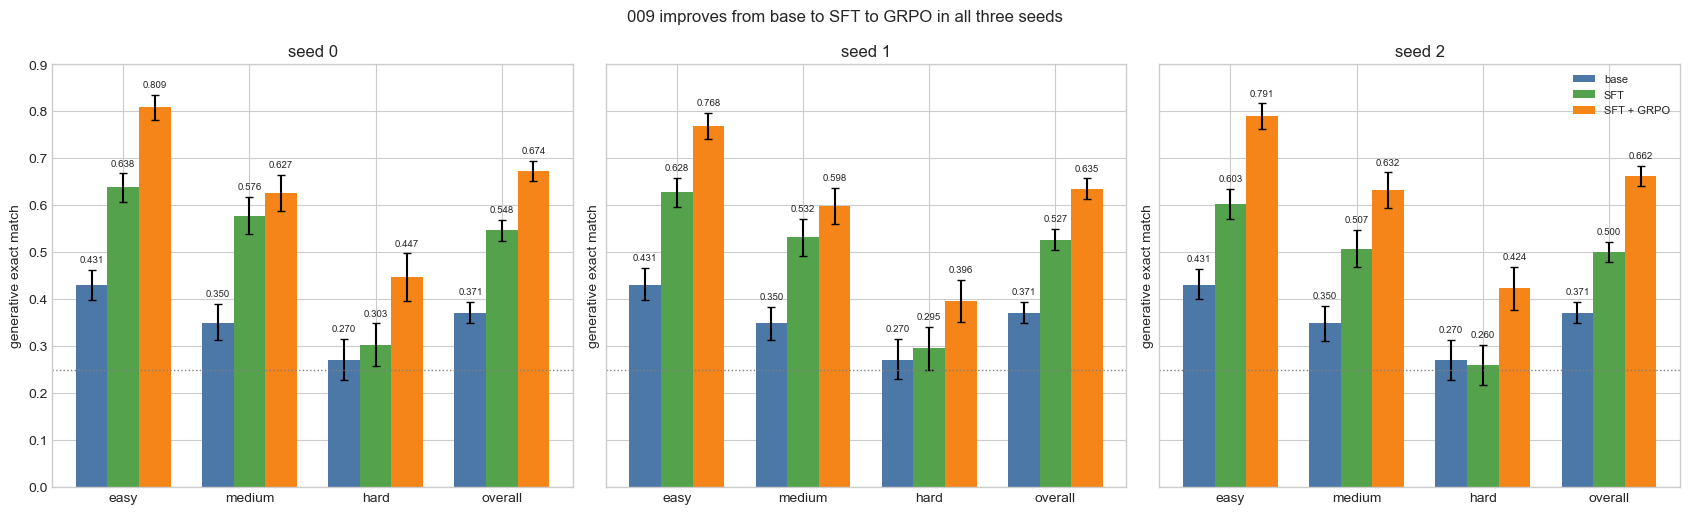

In [6]:
# plot the full base to SFT to GRPO route for all three seeds
xpos = np.arange(len(GROUPS))
width = 0.25
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), sharey=True)
for ax, seed in zip(axes, SEEDS):
    data = D9[seed]
    for index, condition in enumerate(CONDITIONS):
        values = [group_accuracy(data["preds"][condition], group) for group in GROUPS]
        cis = [group_ci(data["preds"][condition], group, seed=900 + seed * 20 + index * 4 + group_index)
               for group_index, group in enumerate(GROUPS)]
        errors = [np.maximum([value - ci[0] for value, ci in zip(values, cis)], 0),
                  np.maximum([ci[1] - value for value, ci in zip(values, cis)], 0)]
        bars = ax.bar(xpos + (index - 1) * width, values, width, yerr=errors, capsize=3,
                      label=CONDITION_LABELS[condition], color=COLORS[condition])
        labels = [f"{value:.3f}" for value in values]
        ax.bar_label(bars, labels=labels, padding=4, fontsize=7)
    ax.axhline(0.25, color="grey", ls=":", lw=1)
    ax.set_xticks(xpos)
    ax.set_xticklabels(GROUPS)
    ax.set_title(f"seed {seed}")
    ax.set_ylim(0, 0.9)
    ax.set_ylabel("generative exact match")
axes[-1].legend(fontsize=8)
fig.suptitle("009 improves from base to SFT to GRPO in all three seeds")
fig.tight_layout()
save(fig, "fig04_pipeline_accuracy")
plt.show()


delta   ci_lo   ci_hi  sft_only_correct  grpo_only_correct  \
seed group                                                                  
0    easy     0.1706  0.1399  0.2014                36                186   
     medium   0.0509  0.0131  0.0903                58                 89   
     hard     0.1439  0.0909  0.1970                33                 90   
     overall  0.1263  0.1040  0.1492               127                365   
1    easy     0.1399  0.1104  0.1718                39                162   
     medium   0.0657  0.0312  0.1018                44                 84   
     hard     0.1010  0.0606  0.1414                16                 56   
     overall  0.1077  0.0881  0.1285                99                302   
2    easy     0.1877  0.1547  0.2218                44                209   
     medium   0.1248  0.0837  0.1642                47                123   
     hard     0.1641  0.1111  0.2172                30                 95   
     overall  0.1624  0.1391  0.1858               121                427   

                 mcnemar_p  holm_p_tiers  
seed group                                
0    easy     0.000000e+00  0.000000e+00  
     medium   1.307770e-02  1.307770e-02  
     hard     2.700000e-07  5.500000e-07  
     overall  0.000000e+00           NaN  
1    easy     0.000000e+00  0.000000e+00  
     medium   5.157800e-04  5.157800e-04  
     hard     2.400000e-06  4.790000e-06  
     overall  0.000000e+00           NaN  
2    easy     0.000000e+00  0.000000e+00  
     medium   0.000000e+00  1.000000e-08  
     hard     0.000000e+00  1.000000e-08  
     overall  0.000000e+00           NaN

saved fig05_grpo_delta


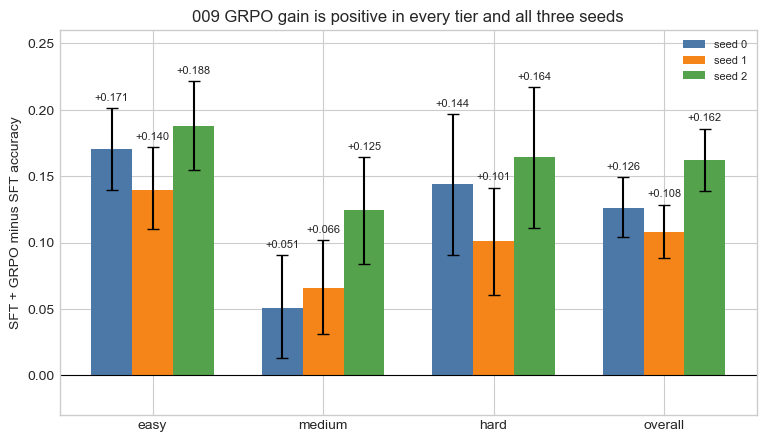

In [7]:
# calculate and plot paired GRPO effects for each seed
GRPO_STATS = {
    seed: paired_stats(D9[seed]["preds"]["sft"], D9[seed]["preds"]["grpo"], seed=950 + seed)
    for seed in SEEDS
}
grpo_stats_tbl = pd.concat([
    pd.DataFrame(rows).assign(seed=seed) for seed, rows in GRPO_STATS.items()
]).set_index(["seed", "group"])
display(grpo_stats_tbl.round({"delta": 4, "ci_lo": 4, "ci_hi": 4, "mcnemar_p": 8, "holm_p_tiers": 8}))

fig, ax = plt.subplots(figsize=(9, 5))
bar_width = 0.24
for index, seed in enumerate(SEEDS):
    rows = GRPO_STATS[seed]
    values = [row["delta"] for row in rows]
    errors = [[row["delta"] - row["ci_lo"] for row in rows],
              [row["ci_hi"] - row["delta"] for row in rows]]
    bars = ax.bar(xpos + (index - 1) * bar_width, values, bar_width, yerr=errors,
                  capsize=4, color=SEED_COLORS[seed], label=f"seed {seed}")
    labels = [f"{value:+.3f}" for value in values]
    ax.bar_label(bars, labels=labels, padding=4, fontsize=8)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(xpos)
ax.set_xticklabels(GROUPS)
ax.set_ylim(-0.03, 0.26)
ax.set_ylabel("SFT + GRPO minus SFT accuracy")
ax.set_title("009 GRPO gain is positive in every tier and all three seeds")
ax.legend(fontsize=8)
save(fig, "fig05_grpo_delta")
plt.show()


## 4. What changed


saved fig06_generation_vs_probe


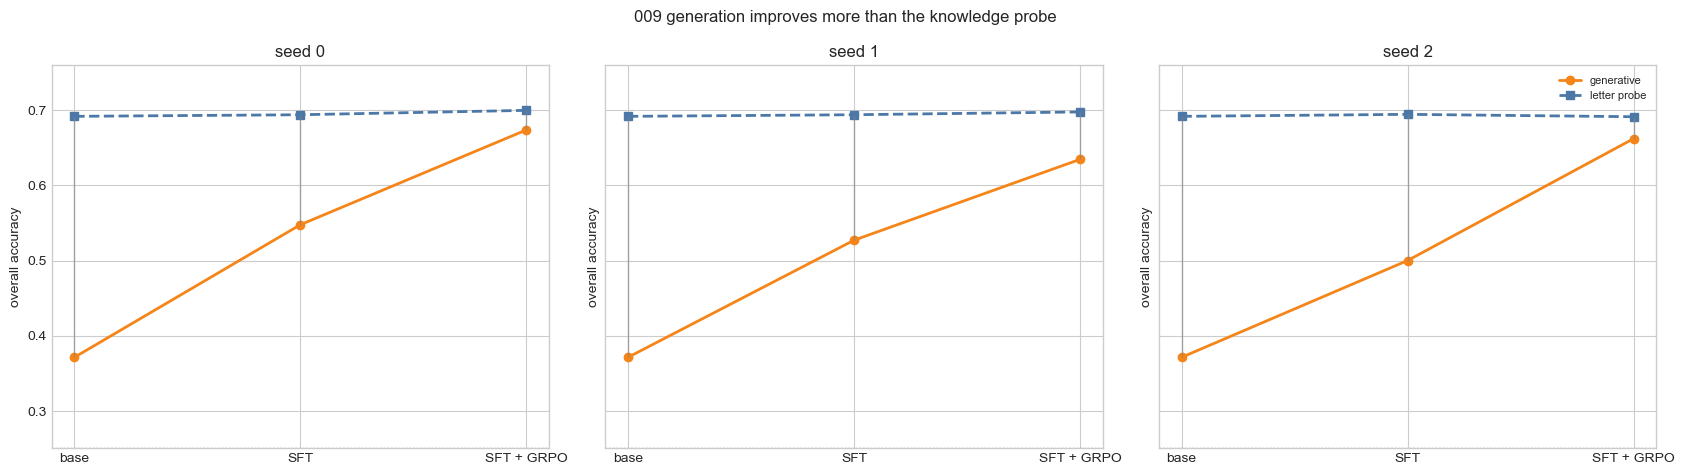

In [8]:
# compare generative accuracy with the letter probe at every stage
positions = np.arange(len(CONDITIONS))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
for ax, seed in zip(axes, SEEDS):
    gen_values = [accuracy(D9[seed]["preds"][condition]) for condition in CONDITIONS]
    probe_values = [accuracy(D9[seed]["lp_preds"][condition]) for condition in CONDITIONS]
    ax.plot(positions, gen_values, "o-", color=COLORS["grpo"], lw=2, label="generative")
    ax.plot(positions, probe_values, "s--", color=COLORS["base"], lw=2, label="letter probe")
    for pos, gen_value, probe_value in zip(positions, gen_values, probe_values):
        ax.vlines(pos, gen_value, probe_value, color="grey", lw=1, alpha=0.6)
    ax.axhline(0.25, color="grey", ls=":", lw=1)
    ax.set_xticks(positions)
    ax.set_xticklabels([CONDITION_LABELS[c] for c in CONDITIONS])
    ax.set_title(f"seed {seed}")
    ax.set_ylim(0.25, 0.76)
    ax.set_ylabel("overall accuracy")
axes[-1].legend(fontsize=8)
fig.suptitle("009 generation improves more than the knowledge probe")
fig.tight_layout()
save(fig, "fig06_generation_vs_probe")
plt.show()


saved fig07_eval_diagnostics


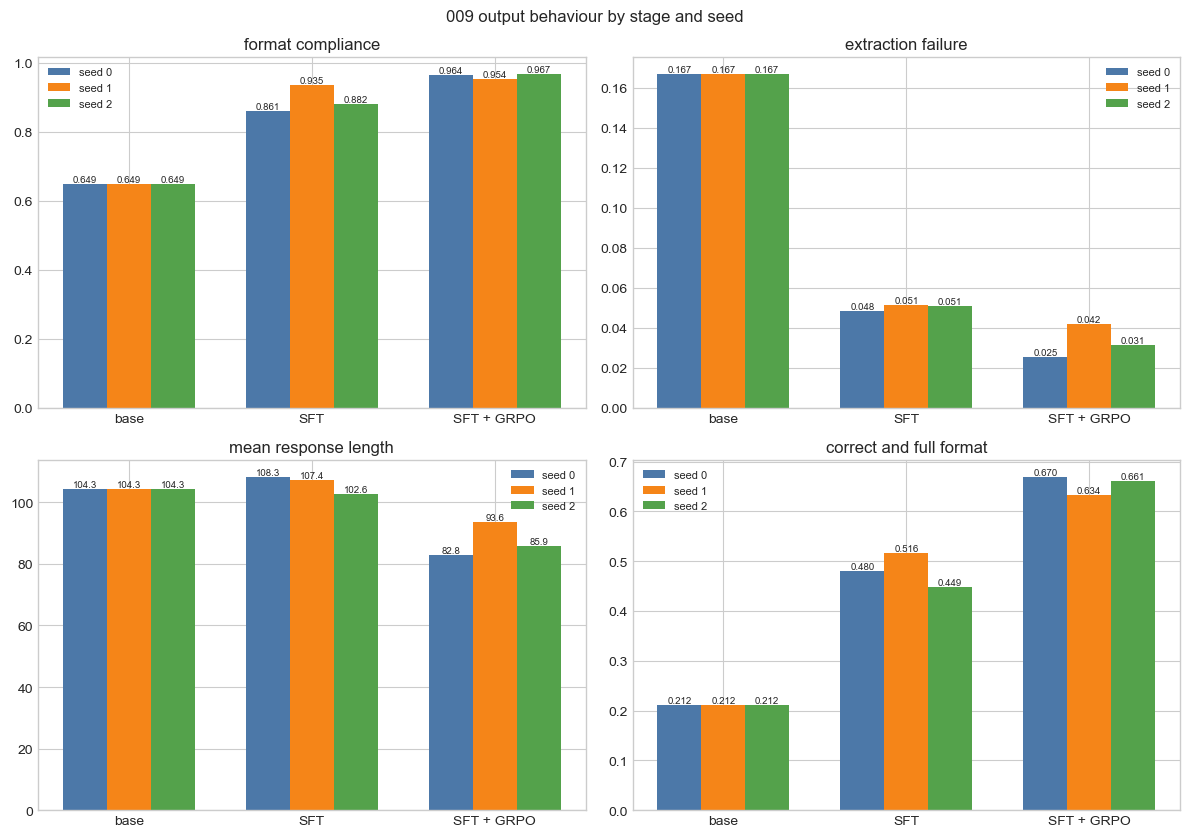

format compliance  extraction failure  mean response length  \
seed condition                                                                
0    base                  0.6492              0.1667              104.2574   
     sft                   0.8609              0.0483              108.3477   
     grpo                  0.9644              0.0255               82.8259   
1    base                  0.6492              0.1667              104.2574   
     sft                   0.9347              0.0515              107.3917   
     grpo                  0.9544              0.0419               93.6173   
2    base                  0.6492              0.1667              104.2574   
     sft                   0.8816              0.0510              102.5934   
     grpo                  0.9671              0.0313               85.9469   

                correct and full format  
seed condition                           
0    base                        0.2118  
     sft                         0.4804  
     grpo                        0.6699  
1    base                        0.2118  
     sft                         0.5165  
     grpo                        0.6338  
2    base                        0.2118  
     sft                         0.4485  
     grpo                        0.6608

In [9]:
# compare format, extraction, response length and correct full-format answers
diagnostic_rows = []
for seed in SEEDS:
    for condition in CONDITIONS:
        predictions = D9[seed]["preds"][condition]
        diagnostic_rows.append({
            "seed": seed,
            "condition": condition,
            "format compliance": D9[seed]["eval"][condition]["format_compliance"],
            "extraction failure": D9[seed]["eval"][condition]["extraction_failure_rate"],
            "mean response length": D9[seed]["eval"][condition]["mean_len"],
            "correct and full format": np.mean([row["correct"] and row["format_ok"] for row in predictions]),
        })
diagnostics_tbl = pd.DataFrame(diagnostic_rows)

fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
metrics = ["format compliance", "extraction failure", "mean response length", "correct and full format"]
for ax, metric in zip(axes.flat, metrics):
    for index, seed in enumerate(SEEDS):
        values = [diagnostics_tbl.query("seed == @seed and condition == @condition")[metric].iloc[0]
                  for condition in CONDITIONS]
        bars = ax.bar(positions + (index - 1) * 0.24, values, 0.24,
                      color=SEED_COLORS[seed], label=f"seed {seed}")
        for bar, value in zip(bars, values):
            label = f"{value:.1f}" if metric == "mean response length" else f"{value:.3f}"
            ax.text(bar.get_x() + bar.get_width() / 2, value, label, ha="center", va="bottom", fontsize=7)
    ax.set_xticks(positions)
    ax.set_xticklabels([CONDITION_LABELS[c] for c in CONDITIONS])
    ax.set_title(metric)
    ax.legend(fontsize=8)
fig.suptitle("009 output behaviour by stage and seed")
fig.tight_layout()
save(fig, "fig07_eval_diagnostics")
plt.show()
display(diagnostics_tbl.set_index(["seed", "condition"]).round(4))


saved fig08_subject_grpo_delta


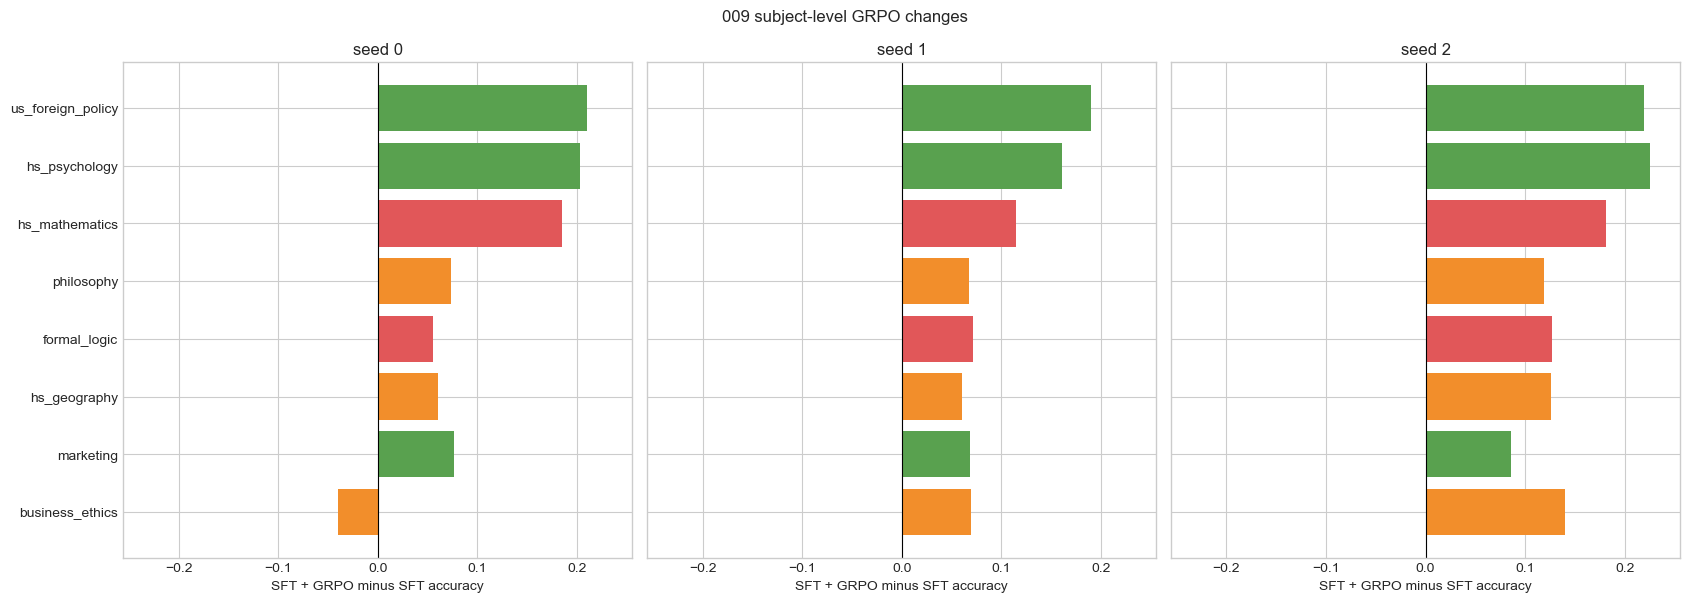

In [10]:
# compare subject-level GRPO changes without hiding the seed difference
subject_rows = []
for seed in SEEDS:
    for subject, sft_value in D9[seed]["eval"]["sft"]["per_subject_acc"].items():
        grpo_value = D9[seed]["eval"]["grpo"]["per_subject_acc"][subject]
        subject_rows.append({
            "seed": seed,
            "subject": subject,
            "tier": TIER_LOOKUP[subject],
            "SFT": sft_value,
            "SFT + GRPO": grpo_value,
            "delta": grpo_value - sft_value,
        })
subject_tbl = pd.DataFrame(subject_rows)
subject_order = subject_tbl.groupby("subject")["delta"].mean().sort_values().index.tolist()
all_deltas = subject_tbl["delta"].tolist()
limit = max(abs(min(all_deltas)), abs(max(all_deltas))) + 0.03

fig, axes = plt.subplots(1, 3, figsize=(17, 6.1), sharex=True, sharey=True)
for ax, seed in zip(axes, SEEDS):
    table = subject_tbl.query("seed == @seed").set_index("subject").loc[subject_order]
    labels = [label.replace("high_school_", "hs_") for label in table.index]
    ax.barh(labels, table["delta"], color=[TIER_COLORS[tier] for tier in table["tier"]])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlim(-limit, limit)
    ax.set_xlabel("SFT + GRPO minus SFT accuracy")
    ax.set_title(f"seed {seed}")
fig.suptitle("009 subject-level GRPO changes")
fig.tight_layout()
save(fig, "fig08_subject_grpo_delta")
plt.show()


## 5. RQ2 scale comparison


params_b    base  base_probe     sft  sft_probe    grpo  \
scale seed                                                            
0.5B  0          0.5  0.1852      0.5669  0.2086     0.5626  0.4623   
      1          0.5  0.1852      0.5669  0.2389     0.5621  0.3153   
      2          0.5  0.1852      0.5669  0.2235     0.5557  0.5058   
1.5B  0          1.5  0.3710      0.6921  0.5478     0.6943  0.6741   
      1          1.5  0.3710      0.6921  0.5271     0.6943  0.6348   
      2          1.5  0.3710      0.6921  0.5000     0.6948  0.6624   
3B    0          3.0  0.5934      0.7362  0.5340     0.7362  0.7160   
      1          3.0  0.5934      0.7362  0.5096     0.7426  0.7266   
      2          3.0  0.5934      0.7362  0.5563     0.7314  0.7272   

            grpo_probe  grpo_gain  
scale seed                         
0.5B  0         0.5679     0.2537  
      1         0.5626     0.0764  
      2         0.5600     0.2824  
1.5B  0         0.7001     0.1263  
      1         0.6980     0.1077  
      2         0.6916     0.1624  
3B    0         0.7410     0.1821  
      1         0.7447     0.2171  
      2         0.7351     0.1709

,params_b,n_seeds,base_mean,base_min,base_max,sft_mean,sft_min,sft_max,grpo_mean,grpo_min,grpo_max,grpo_gain_mean,grpo_gain_min,grpo_gain_max,grpo_probe_mean,grpo_probe_min,grpo_probe_max
scale,,,,,,,,,,,,,,,,,
0.5B,0.5,3,0.1852,0.1852,0.1852,0.2236,0.2086,0.2389,0.4278,0.3153,0.5058,0.2042,0.0764,0.2824,0.5635,0.5600,0.5679
1.5B,1.5,3,0.3710,0.3710,0.3710,0.5249,0.5000,0.5478,0.6571,0.6348,0.6741,0.1322,0.1077,0.1624,0.6966,0.6916,0.7001
3B,3.0,3,0.5934,0.5934,0.5934,0.5333,0.5096,0.5563,0.7233,0.7160,0.7272,0.1900,0.1709,0.2171,0.7403,0.7351,0.7447


saved fig09_scale_curve


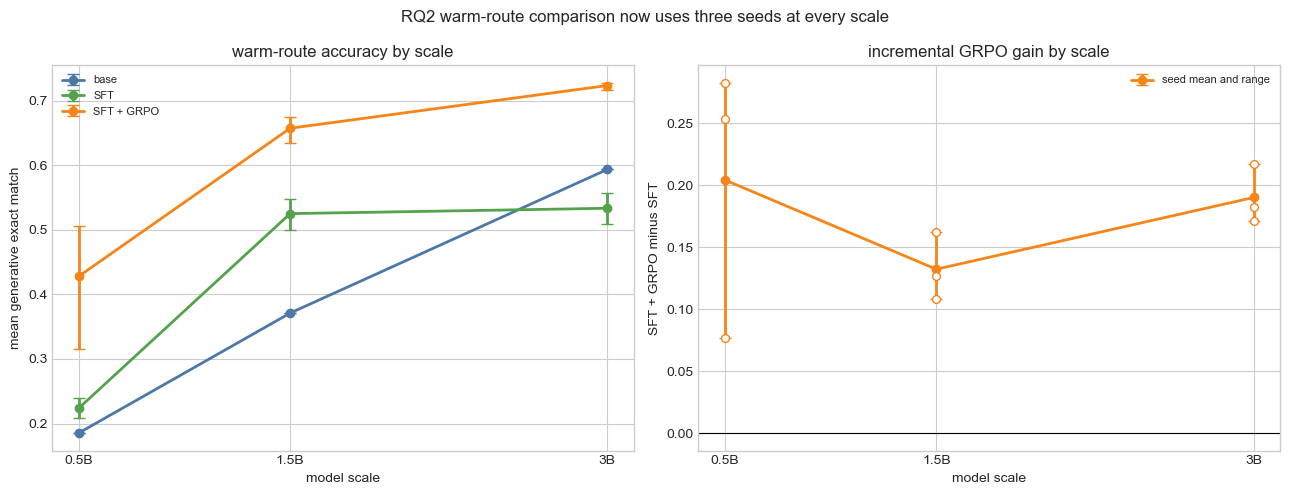

In [11]:
# add the 1.5B point to the matched warm-route scale curve
scale_rows = []
for scale, info in SCALE_RUNS.items():
    for seed in info["seeds"]:
        data = SCALE_DATA[scale][seed]
        row = {"scale": scale, "params_b": info["params"], "seed": seed}
        for condition in CONDITIONS:
            row[condition] = accuracy(data["preds"][condition])
            row[f"{condition}_probe"] = accuracy(data["lp_preds"][condition])
        row["grpo_gain"] = row["grpo"] - row["sft"]
        scale_rows.append(row)
scale_seed_tbl = pd.DataFrame(scale_rows)

summary_rows = []
for (scale, params_b), group in scale_seed_tbl.groupby(["scale", "params_b"], sort=False):
    row = {"scale": scale, "params_b": params_b, "n_seeds": len(group)}
    for key in ["base", "sft", "grpo", "grpo_gain", "grpo_probe"]:
        row[f"{key}_mean"] = group[key].mean()
        row[f"{key}_min"] = group[key].min()
        row[f"{key}_max"] = group[key].max()
    summary_rows.append(row)
scale_summary_tbl = pd.DataFrame(summary_rows).sort_values("params_b").set_index("scale")
display(scale_seed_tbl.set_index(["scale", "seed"]).round(4))
display(scale_summary_tbl.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x = scale_summary_tbl["params_b"].to_numpy()
for condition in CONDITIONS:
    values = scale_summary_tbl[f"{condition}_mean"].to_numpy()
    lower = np.maximum(values - scale_summary_tbl[f"{condition}_min"].to_numpy(), 0)
    upper = np.maximum(scale_summary_tbl[f"{condition}_max"].to_numpy() - values, 0)
    axes[0].errorbar(x, values, yerr=[lower, upper], marker="o", lw=2, capsize=4,
                     color=COLORS[condition], label=CONDITION_LABELS[condition])
axes[0].set_xticks(x)
axes[0].set_xticklabels(scale_summary_tbl.index)
axes[0].set_xlabel("model scale")
axes[0].set_ylabel("mean generative exact match")
axes[0].set_title("warm-route accuracy by scale")
axes[0].legend(fontsize=8)

gain_means = scale_summary_tbl["grpo_gain_mean"].to_numpy()
gain_lo = np.maximum(gain_means - scale_summary_tbl["grpo_gain_min"].to_numpy(), 0)
gain_hi = np.maximum(scale_summary_tbl["grpo_gain_max"].to_numpy() - gain_means, 0)
axes[1].errorbar(x, gain_means, yerr=[gain_lo, gain_hi], marker="o", lw=2,
                 capsize=4, color=COLORS["grpo"], label="seed mean and range")
for scale, info in SCALE_RUNS.items():
    values = scale_seed_tbl.query("scale == @scale")["grpo_gain"].to_numpy()
    axes[1].scatter(np.repeat(info["params"], len(values)), values, s=32, facecolors="white",
                    edgecolors=COLORS["grpo"], zorder=3)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xticks(x)
axes[1].set_xticklabels(scale_summary_tbl.index)
axes[1].set_xlabel("model scale")
axes[1].set_ylabel("SFT + GRPO minus SFT")
axes[1].set_title("incremental GRPO gain by scale")
axes[1].legend(fontsize=8)
fig.suptitle("RQ2 warm-route comparison now uses three seeds at every scale")
fig.tight_layout()
save(fig, "fig09_scale_curve")
plt.show()


saved fig10_scale_generation_vs_probe


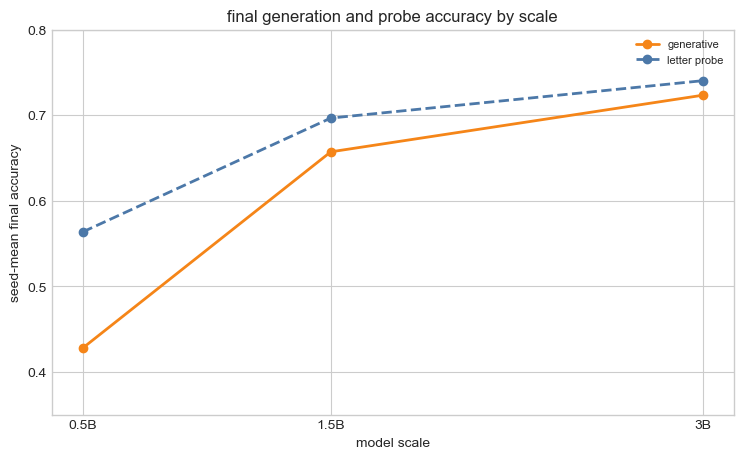

In [12]:
# compare final generative accuracy with the final letter probe across scales
fig, ax = plt.subplots(figsize=(8.8, 5))
for key, label, color, style in [
    ("grpo_mean", "generative", COLORS["grpo"], "-"),
    ("grpo_probe_mean", "letter probe", COLORS["base"], "--"),
]:
    values = scale_summary_tbl[key].to_numpy()
    ax.plot(x, values, marker="o", lw=2, ls=style, color=color, label=label)
ax.set_xticks(x)
ax.set_xticklabels(scale_summary_tbl.index)
ax.set_xlabel("model scale")
ax.set_ylabel("seed-mean final accuracy")
ax.set_ylim(0.35, 0.8)
ax.set_title("final generation and probe accuracy by scale")
ax.legend(fontsize=8)
save(fig, "fig10_scale_generation_vs_probe")
plt.show()


## 6. Compute and numeric tables

,seed_0_hours,seed_1_hours,seed_2_hours
base_eval,0.544,0.000,0.000
base_logprob_eval,0.005,0.000,0.000
sft_train,0.209,0.207,0.219
sft_eval,1.076,0.997,0.913
sft_logprob_eval,0.007,0.007,0.005
grpo_train,3.068,3.004,2.957
grpo_eval,0.687,0.800,0.708
grpo_logprob_eval,0.007,0.007,0.006
total,5.602,5.022,4.808


saved fig11_compute_timing


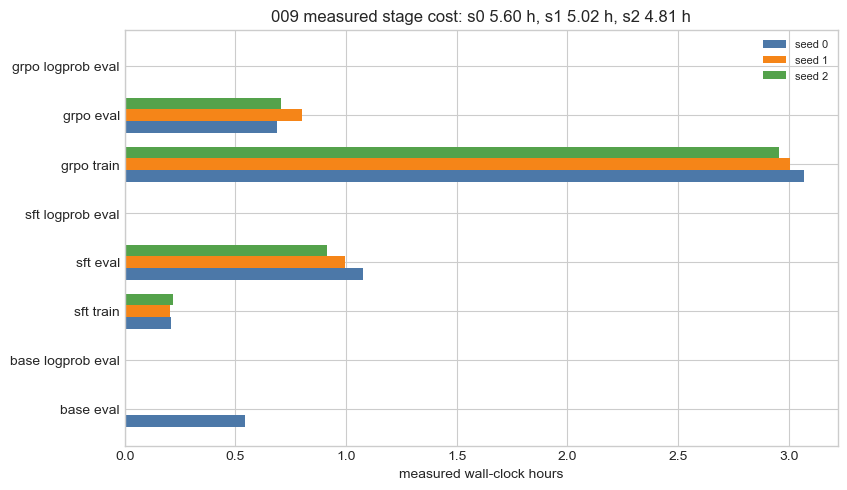

base evaluation appears only under seed 0 because seeds 1 and 2 reused it
closed 009 compute-unit usage: 73.99
the seed 2 compute-unit record is still open and is excluded from this total


In [13]:
# compare measured stage time and keep reused base evaluation separate
stage_order = ["base_eval", "base_logprob_eval", "sft_train", "sft_eval", "sft_logprob_eval",
               "grpo_train", "grpo_eval", "grpo_logprob_eval"]
compute_tbl = pd.DataFrame({
    f"seed_{seed}_hours": [D9[seed]["man"]["timings_sec"].get(stage, 0) / 3600 for stage in stage_order]
    for seed in SEEDS
}, index=stage_order)
compute_tbl.loc["total"] = compute_tbl.sum()
display(compute_tbl.round(3))

plot_tbl = compute_tbl.drop(index="total")
y = np.arange(len(plot_tbl))
fig, ax = plt.subplots(figsize=(9.2, 5.4))
bar_height = 0.24
for index, seed in enumerate(SEEDS):
    values = plot_tbl[f"seed_{seed}_hours"].to_numpy()
    ax.barh(y + (index - 1) * bar_height, values, bar_height,
            color=SEED_COLORS[seed], label=f"seed {seed}")
ax.set_yticks(y)
ax.set_yticklabels([label.replace("_", " ") for label in plot_tbl.index])
ax.set_xlabel("measured wall-clock hours")
totals = ", ".join(f"s{seed} {compute_tbl.loc['total', f'seed_{seed}_hours']:.2f} h" for seed in SEEDS)
ax.set_title(f"009 measured stage cost: {totals}")
ax.legend(fontsize=8)
save(fig, "fig11_compute_timing")
plt.show()
print("base evaluation appears only under seed 0 because seeds 1 and 2 reused it")
closed_unit_records = [row for row in unit_records if row.get("colab_cu_used") is not None]
print(f"closed 009 compute-unit usage: {sum(row['colab_cu_used'] for row in closed_unit_records):.2f}")
if open_unit_records:
    print("the seed 2 compute-unit record is still open and is excluded from this total")


In [14]:
# keep the exact endpoint values behind the plots
accuracy_rows = []
for seed in SEEDS:
    for condition in CONDITIONS:
        row = {"seed": seed, "condition": CONDITION_LABELS[condition]}
        for tier in TIERS:
            row[f"gen_{tier}"] = group_accuracy(D9[seed]["preds"][condition], tier)
            row[f"probe_{tier}"] = group_accuracy(D9[seed]["lp_preds"][condition], tier)
        row["gen_overall"] = accuracy(D9[seed]["preds"][condition])
        row["probe_overall"] = accuracy(D9[seed]["lp_preds"][condition])
        accuracy_rows.append(row)
accuracy_tbl = pd.DataFrame(accuracy_rows).set_index(["seed", "condition"])
display(accuracy_tbl.round(4))

for seed in SEEDS:
    print(f"009 SFT to GRPO subject deltas, seed {seed}")
    display(subject_tbl.query("seed == @seed").set_index("subject").drop(columns="seed").round(4))


gen_easy  probe_easy  gen_medium  probe_medium  gen_hard  \
seed condition                                                              
0    base          0.4312      0.8146      0.3498        0.6946    0.2702   
     SFT           0.6382      0.8100      0.5764        0.6929    0.3030   
     SFT + GRPO    0.8089      0.8123      0.6273        0.7077    0.4470   
1    base          0.4312      0.8146      0.3498        0.6946    0.2702   
     SFT           0.6280      0.8123      0.5320        0.6979    0.2955   
     SFT + GRPO    0.7679      0.8134      0.5977        0.6995    0.3965   
2    base          0.4312      0.8146      0.3498        0.6946    0.2702   
     SFT           0.6030      0.8111      0.5074        0.7028    0.2601   
     SFT + GRPO    0.7907      0.8089      0.6322        0.7028    0.4242   

                 probe_hard  gen_overall  probe_overall  
seed condition                                           
0    base            0.4167       0.3710         0.6921  
     SFT             0.4394       0.5478         0.6943  
     SFT + GRPO      0.4394       0.6741         0.7001  
1    base            0.4167       0.3710         0.6921  
     SFT             0.4268       0.5271         0.6943  
     SFT + GRPO      0.4394       0.6348         0.6980  
2    base            0.4167       0.3710         0.6921  
     SFT             0.4242       0.5000         0.6948  
     SFT + GRPO      0.4141       0.6624         0.6916

009 SFT to GRPO subject deltas, seed 0


,tier,SFT,SFT + GRPO,delta
subject,,,,
high_school_psychology,easy,0.6073,0.8110,0.2037
marketing,easy,0.7436,0.8205,0.0769
us_foreign_policy,easy,0.5600,0.7700,0.2100
high_school_geography,medium,0.6364,0.6970,0.0606
philosophy,medium,0.5209,0.5949,0.0740
business_ethics,medium,0.6300,0.5900,-0.0400
high_school_mathematics,hard,0.2630,0.4481,0.1852
formal_logic,hard,0.3889,0.4444,0.0556


009 SFT to GRPO subject deltas, seed 1


,tier,SFT,SFT + GRPO,delta
subject,,,,
high_school_psychology,easy,0.6037,0.7651,0.1615
marketing,easy,0.7265,0.7949,0.0684
us_foreign_policy,easy,0.5300,0.7200,0.1900
high_school_geography,medium,0.5909,0.6515,0.0606
philosophy,medium,0.4855,0.5531,0.0675
business_ethics,medium,0.5600,0.6300,0.0700
high_school_mathematics,hard,0.2704,0.3852,0.1148
formal_logic,hard,0.3492,0.4206,0.0714


009 SFT to GRPO subject deltas, seed 2


,tier,SFT,SFT + GRPO,delta
subject,,,,
high_school_psychology,easy,0.5596,0.7853,0.2257
marketing,easy,0.7308,0.8162,0.0855
us_foreign_policy,easy,0.5400,0.7600,0.2200
high_school_geography,medium,0.5859,0.7121,0.1263
philosophy,medium,0.4598,0.5788,0.1190
business_ethics,medium,0.5000,0.6400,0.1400
high_school_mathematics,hard,0.2333,0.4148,0.1815
formal_logic,hard,0.3175,0.4444,0.1270


## 7. Three-seed stability

saved fig12_three_seed_stability


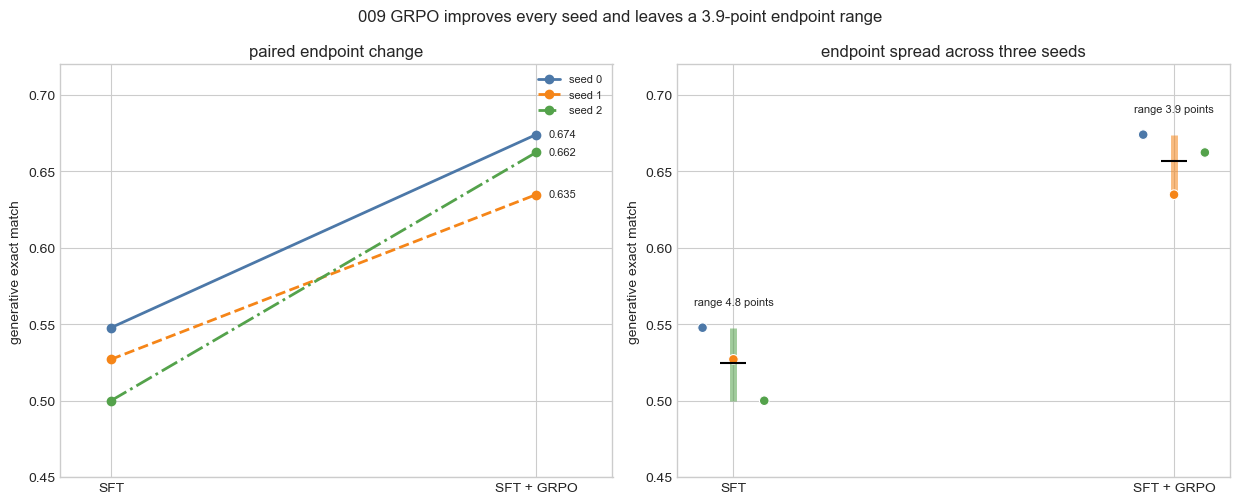

mean paired GRPO gain: 13.22 points


In [15]:
# compare paired endpoints and their spread across the three seeds
sft_endpoints = np.asarray([accuracy(D9[seed]["preds"]["sft"]) for seed in SEEDS])
grpo_endpoints = np.asarray([accuracy(D9[seed]["preds"]["grpo"]) for seed in SEEDS])

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.1))
for index, seed in enumerate(SEEDS):
    values = [sft_endpoints[index], grpo_endpoints[index]]
    axes[0].plot([0, 1], values, marker="o", lw=2, color=SEED_COLORS[seed],
                 ls=SEED_STYLES[seed], label=f"seed {seed}")
    axes[0].text(1.03, values[1], f"{values[1]:.3f}", va="center", fontsize=8)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["SFT", "SFT + GRPO"])
axes[0].set_xlim(-0.12, 1.18)
axes[0].set_ylim(0.45, 0.72)
axes[0].set_ylabel("generative exact match")
axes[0].set_title("paired endpoint change")
axes[0].legend(fontsize=8)

for position, (label, values, color) in enumerate([
    ("SFT", sft_endpoints, COLORS["sft"]),
    ("SFT + GRPO", grpo_endpoints, COLORS["grpo"]),
]):
    axes[1].vlines(position, values.min(), values.max(), color=color, lw=5, alpha=0.55)
    offsets = np.linspace(-0.07, 0.07, len(values))
    axes[1].scatter(position + offsets, values, s=48, color=[SEED_COLORS[seed] for seed in SEEDS],
                    edgecolor="white", linewidth=0.8, zorder=3)
    axes[1].scatter(position, values.mean(), marker="_", s=330, color="black", zorder=4)
    axes[1].text(position, values.max() + 0.015,
                 f"range {100 * (values.max() - values.min()):.1f} points",
                 ha="center", fontsize=8)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["SFT", "SFT + GRPO"])
axes[1].set_ylim(0.45, 0.72)
axes[1].set_ylabel("generative exact match")
axes[1].set_title("endpoint spread across three seeds")

fig.suptitle("009 GRPO improves every seed and leaves a 3.9-point endpoint range")
fig.tight_layout()
save(fig, "fig12_three_seed_stability")
plt.show()
print(f"mean paired GRPO gain: {100 * np.mean(grpo_endpoints - sft_endpoints):.2f} points")

saved fig13_cross_scale_seed_spread


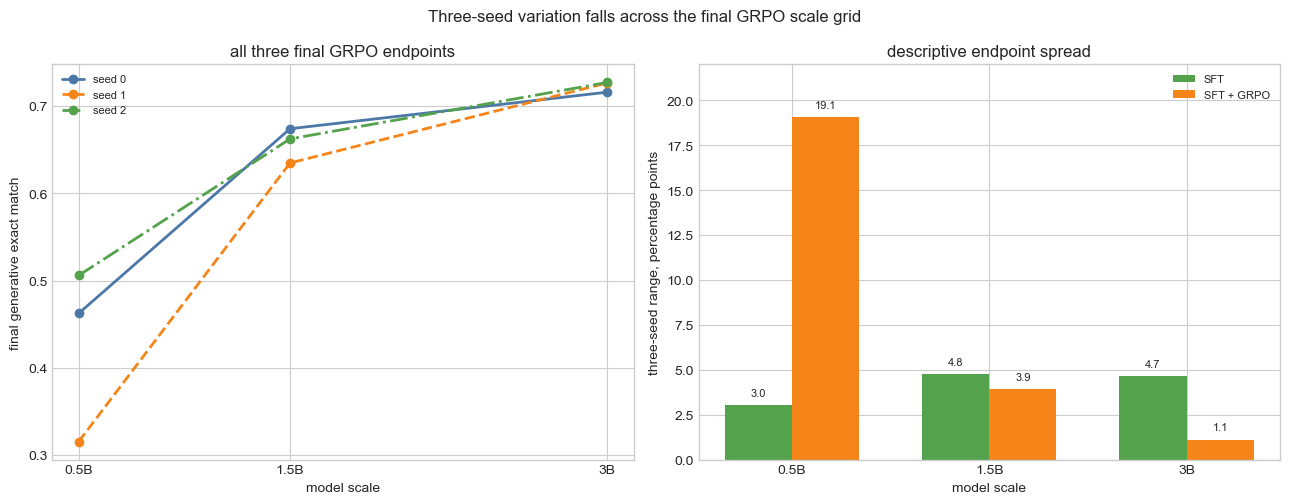

In [16]:
# compare three-seed endpoint variation across the matched scale grid
fig, axes = plt.subplots(1, 2, figsize=(13, 5.1))
for seed in SEEDS:
    table = scale_seed_tbl.query("seed == @seed").sort_values("params_b")
    axes[0].plot(table["params_b"], table["grpo"], marker="o", lw=2,
                 color=SEED_COLORS[seed], ls=SEED_STYLES[seed], label=f"seed {seed}")
axes[0].set_xticks(x)
axes[0].set_xticklabels(scale_summary_tbl.index)
axes[0].set_xlabel("model scale")
axes[0].set_ylabel("final generative exact match")
axes[0].set_title("all three final GRPO endpoints")
axes[0].legend(fontsize=8)

spread_x = np.arange(len(scale_summary_tbl))
spread_width = 0.34
for index, (condition, label) in enumerate([("sft", "SFT"), ("grpo", "SFT + GRPO")]):
    values = 100 * (scale_summary_tbl[f"{condition}_max"] - scale_summary_tbl[f"{condition}_min"])
    bars = axes[1].bar(spread_x + (index - 0.5) * spread_width, values, spread_width,
                       color=COLORS[condition], label=label)
    for bar, value in zip(bars, values):
        axes[1].text(bar.get_x() + bar.get_width() / 2, value + 0.5, f"{value:.1f}",
                     ha="center", fontsize=8)
axes[1].set_xticks(spread_x)
axes[1].set_xticklabels(scale_summary_tbl.index)
axes[1].set_xlabel("model scale")
axes[1].set_ylabel("three-seed range, percentage points")
axes[1].set_title("descriptive endpoint spread")
axes[1].set_ylim(0, 22)
axes[1].legend(fontsize=8)

fig.suptitle("Three-seed variation falls across the final GRPO scale grid")
fig.tight_layout()
save(fig, "fig13_cross_scale_seed_spread")
plt.show()

## Cross-referenced conclusion

All three 009 seeds finished normally on A100 80GB GPUs. Each run reached 500 SFT steps,
500 GRPO steps and all 1,884 evaluation items. The runs took 5.60, 5.02 and 4.81 stage hours.
The shared base evaluation was reused by seeds 1 and 2.

The main result is consistent across all three seeds. Overall generative accuracy moves from
54.8% to 67.4% in seed 0, from 52.7% to 63.5% in seed 1, and from 50.0% to 66.2% in seed 2.
The paired GRPO gains are 12.6, 10.8 and 16.2 points, with a mean gain of 13.2 points. Every
tier improves in every seed. Seven of eight subjects improve in seed 0 and all eight improve
in seeds 1 and 2, so the result is not driven by one subject.

The letter probe changes by only +0.6, +0.4 and -0.3 points after GRPO. Format compliance also
rises from 86.1%, 93.5% and 88.2% to 96.4%, 95.4% and 96.7%. This supports an elicitation and
output-control explanation more than new stored knowledge, although the probe cannot fully
separate those mechanisms.

With three seeds at every scale, mean final GRPO accuracy is 42.8 % at 0.5B, 65.7% at 1.5B and
72.3% at 3B. The mean incremental GRPO gains are 20.4, 13.2 and 19.0 points, so the gain itself
is not monotonic. The final GRPO seed range falls from 19.1 points at 0.5B to 3.9 at 1.5B and
1.1 at 3B. This is useful evidence about stability in this grid, but three seeds remain too few
for a general scaling law.

The aggregate ledger contains all three runs. The closed compute-unit record covers the earlier
009 session, while the seed 2 closing balance is still missing. This leaves the compute-unit
total incomplete but does not affect the recorded training or evaluation results.